# Experimental step response of a series RLC circuit. 

$~~~~~~$

<div style='text-align: justify;'>
This programming book presents the procedure and code for obtaining the response to the step of a series RLC circuit. The  comparing the experiemental results to a simulation made using the MatLab kernel. The circuit is made up of a 127 to 12 volt transformer with a maximum output current of 0.25 Amp whose primary coil is the one used as the inductance of 15.1 $H$. The resistor is a 5 $K\Omega$ potentiometer and the capacitor is 1 $\mu F$ electrolytic. The step has an amplitude of 1.63 Volts generated through the digital-analog converter of an Arduino Due board. The mentioned elements are shown in the figure below.
</div>

$~~~~~~$

<center>
<img src="images/RLC.jpg" width="300"/>
</center>

###  The following lines are necessary to establish communication with the Arduino bard, next, to stablish the number of samples to acquire:

$~~~~~~$

<center>
<img src="images/diagrama_USB_ingles.jpg" width="600"/>
</center>



Transfer function 'G' from input 'u1' to output ...

            9.904e+04       
 y1:  ----------------------
      s^2 + 106 s + 6.02e+04

Continuous-time model.


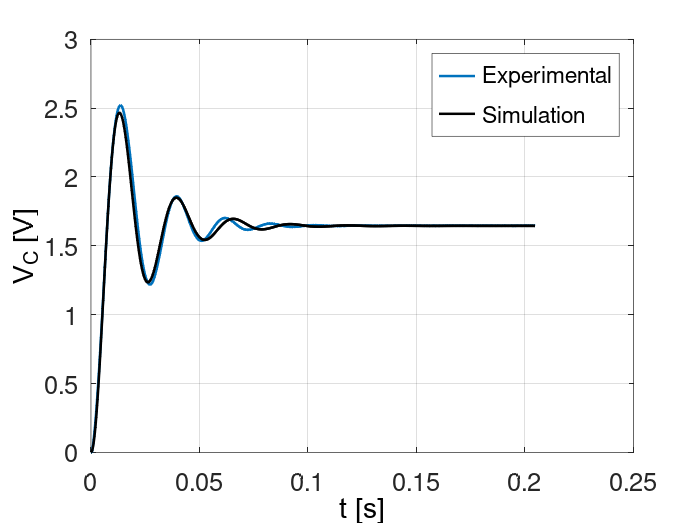

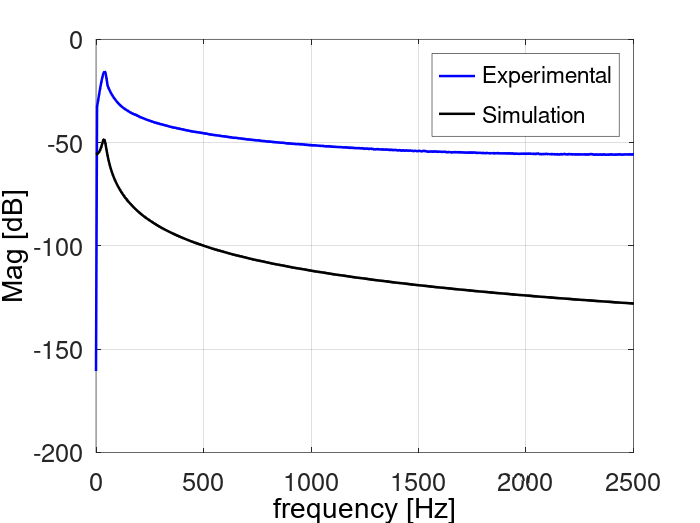

In [3]:
clear
close all
clc
pkg load instrument-control
pkg load signal
pkg load control

s = serial("COM4",2000000);

nSamples=2^10;
samplingRate=5000;
fopen(s);


srl_write(s,int2str (nSamples)); 
srl_write(s,"\n"); 
srl_write(s,int2str (samplingRate)); 
fwrite(s,"\n"); 

data=[];
readData=[];

for i=1:nSamples/256
  readData=fread(s,512,"uint16");
  data=[data readData];
end 
fclose(s)
clear s

t=[0:1/samplingRate:(nSamples-1)*(1/samplingRate)];
adq=data(find(data<(2^13)));

v_c=((3.3/4095)*cast(adq,"single"));

figure
plot(t,v_c,'LineWidth',2)
 
hold on

R=1600;
C=1.1*(10^(-6));
L=15.1;

num=[1.645/(L*C)];
den=[1 R/L 1/(L*C)];
G=tf(num,den)

[y,to]=step(G,t);

plot(to,y,'-k','LineWidth',2)
grid

legend('Experimental','Simulation')
set(gca,'defaulttextinterpreter','latex')
  set(get(gca,'XLabel'),'String','t [s]',...
                    'FontName','Arial',...
                    'FontAngle','normal',...
                    'FontSize',30)
% 
                
         set(get(gca,'YLabel'),'String','V_C [V]',...
                    'FontName','Arial',...
                    'FontAngle','normal',...
                    'FontSize',30)
             
    set(gca,'FontSize',30)
set(gcf,'Visible','on')

 Fs=1/(t(2)-t(1));% determinaciÃ³n de la frecuencia de muestreo
 n=(size(t));% nÃºmero total de muestras a utilizar
 NFFT = 2^nextpow2(max(n));% resoluciÃ³n Ã³ptima para el cÃ¡lculo de la FFT
 f = (Fs/2).*linspace(0,1,NFFT/2);

 Y= fft((v_c-mean(v_c)),NFFT)/(max(n)/2);%Calculo de la FFT, x es el nombre del vector de salida
 r=Y(1:NFFT/2);%solo se toma la parte de las frecuencias positivas es decir, la mitad del espectro
 
 
   [mag,ph,w]=bode(G,f*2*pi);
   dB=20*log10(mag(:,1))-60;
 

     figure  
   plot(f,20*log10(abs(r)),'-b','LineWidth',2) % se grafica la magnitud contra la frecuencia.
   hold on
   plot(f,dB,'-k','LineWidth',2)
 grid
 set(gcf,'Visible','on')
   legend('Experimental','Simulation')
set(gca,'defaulttextinterpreter','latex')
  set(get(gca,'XLabel'),'String','frequency [Hz]',...
                    'FontName','Arial',...
                    'FontAngle','normal',...
                    'FontSize',30)
% 
                
         set(get(gca,'YLabel'),'String','Mag [dB]',...
                    'FontName','Arial',...
                    'FontAngle','normal',...
                    'FontSize',30)
             
    set(gca,'FontSize',30)


Transfer function 'G' from input 'u1' to output ...

            9.904e+04       
 y1:  ----------------------
      s^2 + 106 s + 6.02e+04

Continuous-time model.


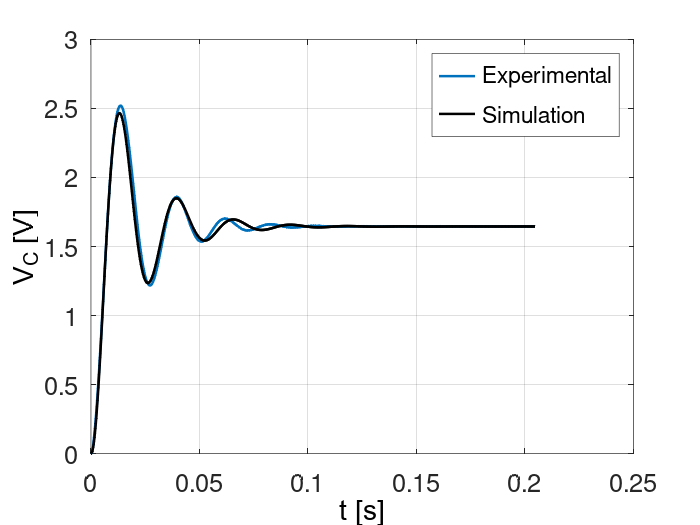

In [5]:
clear
close all
clc
pkg load instrument-control
pkg load signal
pkg load control

s = serial("COM4",2000000);

n_muestras=2^10;
frec_muestreo=5000;
fopen(s);


srl_write(s,int2str (n_muestras)); 
srl_write(s,"\n"); 
srl_write(s,int2str (frec_muestreo)); 
fwrite(s,"\n"); 

datos=[];
datos_leidos=[];

for i=1:n_muestras/256
  datos_leidos=fread(s,512,"uint16");
  datos=[datos datos_leidos];
end 
fclose(s)
clear s

t=[0:1/frec_muestreo:(n_muestras-1)*(1/frec_muestreo)];
adq=datos(find(datos<(2^13)));

v_c=((3.3/4095)*cast(adq,"single"));

figure
plot(t,v_c,'LineWidth',2)
 
hold on

R=1600;
C=1.1*(10^(-6));
L=15.1;

num=[1.645/(L*C)];
den=[1 R/L 1/(L*C)];
G=tf(num,den)

[y,to]=step(G,t);

plot(to,y,'-k','LineWidth',2)
grid

legend('Experimental','Simulation')
set(gca,'defaulttextinterpreter','latex')
  set(get(gca,'XLabel'),'String','t [s]',...
                    'FontName','Arial',...
                    'FontAngle','normal',...
                    'FontSize',30)
% 
                
         set(get(gca,'YLabel'),'String','V_C [V]',...
                    'FontName','Arial',...
                    'FontAngle','normal',...
                    'FontSize',30)
             
    set(gca,'FontSize',30)
set(gcf,'Visible','on')